## One-step-delayed increases

Assign the generic-domain or history-contribution difference at step $i+1$ to candidate error step $i$. These signals need a future step; the final step is unscorable. No model inference.

,signal,subset,auc,steps,first_errors,coverage
0,generic_increase_next,eligible,0.655523,6012,508,0.857387
1,generic_increase_next,common,0.655523,6012,508,0.857387
2,generic_increase_next,all_steps_neutral,0.676707,7012,508,0.857387
3,history_increase_next,eligible,0.636044,6012,508,0.857387
4,history_increase_next,common,0.636044,6012,508,0.857387
5,history_increase_next,all_steps_neutral,0.668395,7012,508,0.857387


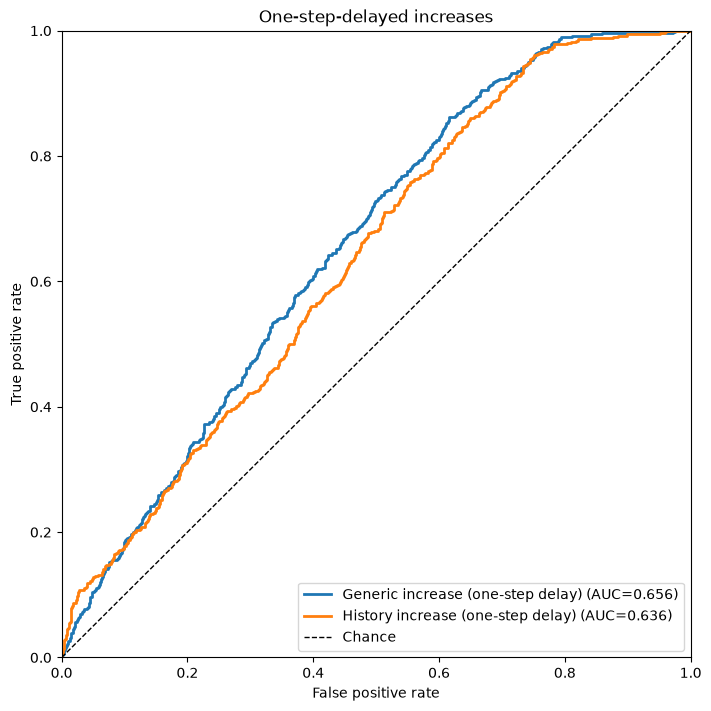

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve().parent
assert ROOT.name == "mr-gsm8k", "Run this notebook from signal_experiments/"
sys.path.insert(0, str(ROOT))
from plots import plot_first_error_roc, plot_first_error_trajectories
from score_dc_pmi import SIGNAL_TITLES, evaluate_signal_scores, load_signal_cache

steps = load_signal_cache(
    ROOT / "cache/llama_3_mr_gsm8k_original_n1000_seed42_token_logprobs.parquet",
    ROOT / "signal_experiments/cache/signals_n1000_seed42.parquet",
)
assert steps.uuid.nunique() == 1000
columns = ["generic_increase_next", "history_increase_next"]
results = evaluate_signal_scores(steps, columns)
display(results)
fig, ax, roc_rows = plot_first_error_roc(
    steps.first_error, {SIGNAL_TITLES[column]: steps[column] for column in columns},
    title="One-step-delayed increases",
)
plt.show()

## Signals around the first error

In incorrect solutions, relative step 0 is the annotated first error. The value at step $i$ uses the difference from $i$ to $i+1$; missing final-step values are omitted. Lines show mean scores across solutions with 95% confidence intervals. Later steps are shown for context, not independently labeled as incorrect.

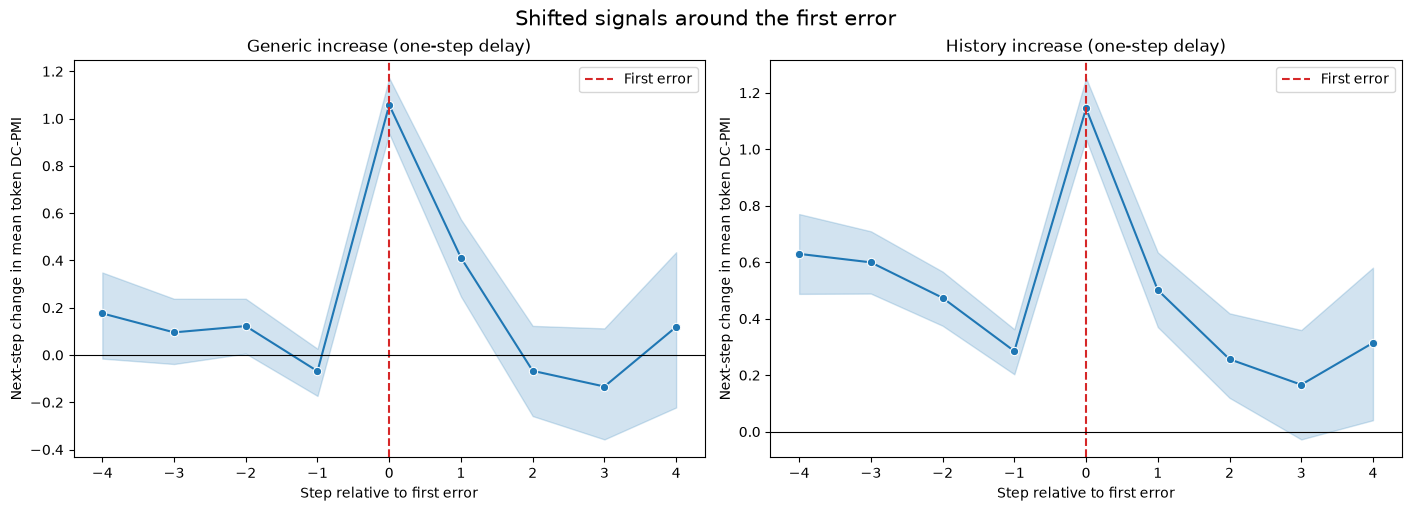

In [2]:
ERROR_CLIFF_WINDOW = 4
fig, axes = plot_first_error_trajectories(
    steps,
    {column: SIGNAL_TITLES[column] for column in columns},
    window=ERROR_CLIFF_WINDOW,
    title="Shifted signals around the first error",
    ylabels={column: "Next-step change in mean token DC-PMI" for column in columns},
    figsize=(14, 5),
)
plt.show()

## Signal distributions at individual steps

Compare annotated first errors against one verified correct control sampled without replacement at the **same absolute step number** for each error. Optionally overlay all eligible verified correct steps (which include the sampled controls). Histograms share bins and show **density**, not raw counts, because group sizes differ. Sampling uses a fixed seed; final steps lacking the next-step signal are excluded.

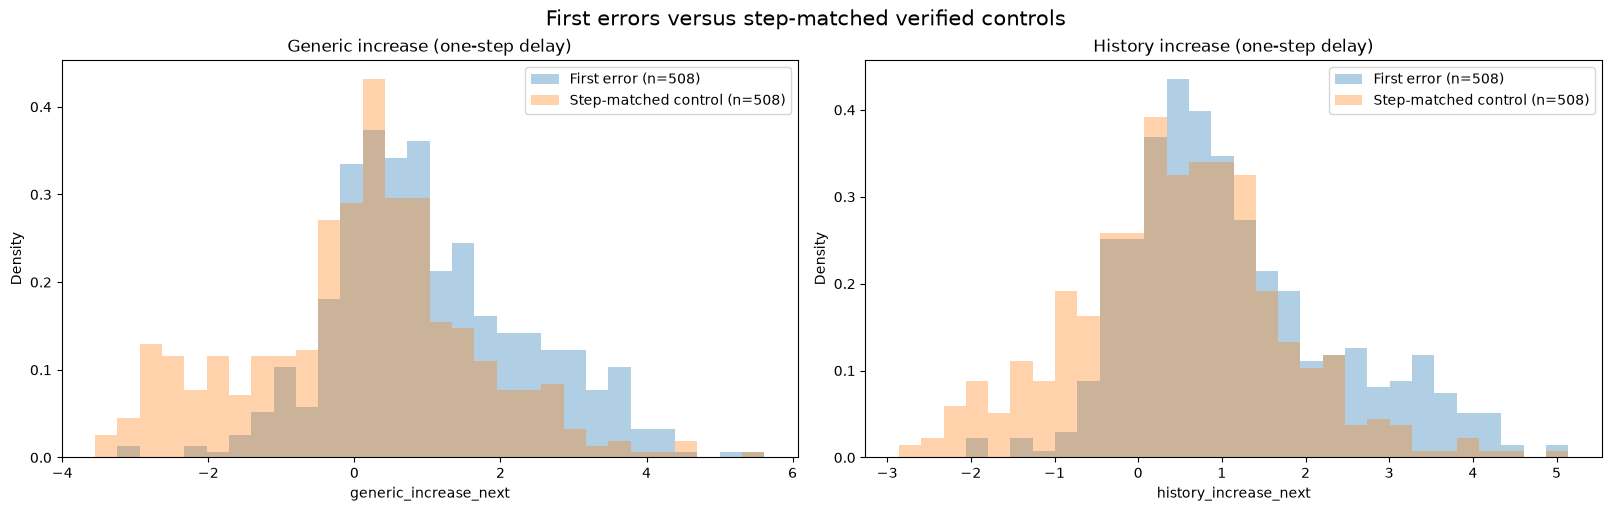

In [3]:
from plots import plot_first_error_histogram

SHOW_ALL_VERIFIED_CORRECT = False
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
for ax, column in zip(axes, columns):
    _, _, groups = plot_first_error_histogram(
        steps, column, title=SIGNAL_TITLES[column], seed=42, bins=30, ax=ax,
        show_all_verified_correct=SHOW_ALL_VERIFIED_CORRECT,
    )
    assert groups["First error"].groupby("step").size().equals(
        groups["Step-matched control"].groupby("step").size()
    )
fig.suptitle("First errors versus step-matched verified controls", fontsize=15)
plt.show()